<a href="https://colab.research.google.com/github/2025csmnikhilsaid-jpg/DAV/blob/main/Lab_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# K-MEANS CLUSTERING USING RANDOM INITIALIZATION

# Step 1: Import required libraries
import os
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from matplotlib.patches import Circle

# Step 2: Create student dataset

data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F'],
    'StudyHours': [1, 2, 3, 8, 9, 10],
    'Marks': [30, 35, 40, 80, 85, 90]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)

# Step 3: Select input features

X = df[['StudyHours', 'Marks']]

Student Dataset:
  Student  StudyHours  Marks
0       A           1     30
1       B           2     35
2       C           3     40
3       D           8     80
4       E           9     85
5       F          10     90


In [ ]:
# Step 4: Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=2,
    init='random',
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

print("\nStudent Groups:")
print(df)


# Step 5: Display final centroids

centroids = kmeans.cluster_centers_

print("\nFinal Centroids:")
print(centroids)


Student Groups:
  Student  StudyHours  Marks  Cluster
0       A           1     30        0
1       B           2     35        0
2       C           3     40        0
3       D           8     80        1
4       E           9     85        1
5       F          10     90        1

Final Centroids:
[[ 2. 35.]
 [ 9. 85.]]


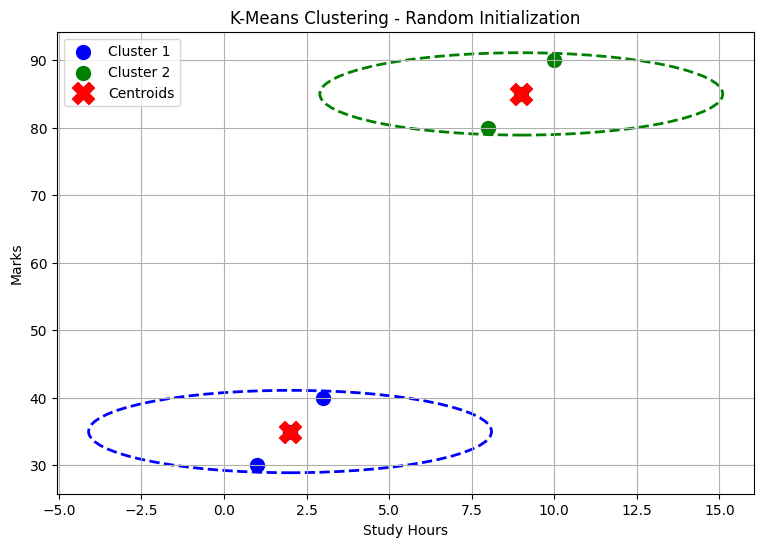

In [ ]:
# Step 6: Visualize two clusters with circles

plt.figure(figsize=(9, 6))

colors = ['blue', 'green']

for cluster in range(2):

    # Select students belonging to each cluster
    cluster_data = df[df['Cluster'] == cluster]

    # Plot student points
    plt.scatter(
        cluster_data['StudyHours'],
        cluster_data['Marks'],
        color=colors[cluster],
        s=100,
        label=f'Cluster {cluster + 1}'
    )

    # Calculate centroid position
    center_x = centroids[cluster, 0]
    center_y = centroids[cluster, 1]

    # Calculate maximum distance from centroid
    distances = (
        (cluster_data['StudyHours'] - center_x) ** 2 +
        (cluster_data['Marks'] - center_y) ** 2
    ) ** 0.5

    radius = distances.max() + 1

    # Draw dashed circle around cluster
    circle = Circle(
        (center_x, center_y),
        radius,
        fill=False,
        color=colors[cluster],
        linewidth=2,
        linestyle='--'
    )

    plt.gca().add_patch(circle)
    # Step 7: Mark the centroids

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.title('K-Means Clustering - Random Initialization')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Step 8: Elbow Method - Calculate WCSS

wcss = []

for k in range(1, 6):

    model = KMeans(
        n_clusters=k,
        init='random',
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss.append(model.inertia_)

# Display WCSS values

print("\nWCSS Values:")

for k, value in enumerate(wcss, start=1):
    print(f"K = {k}, WCSS = {value:.2f}")


WCSS Values:
K = 1, WCSS = 3927.50
K = 2, WCSS = 104.00
K = 3, WCSS = 65.00
K = 4, WCSS = 26.00
K = 5, WCSS = 13.00


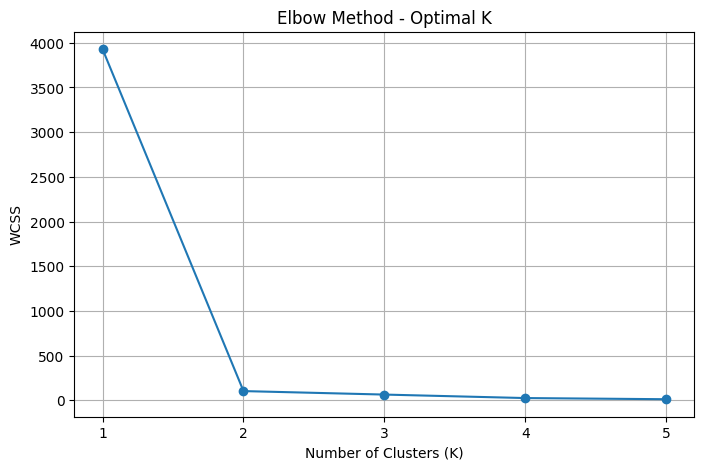

In [ ]:
# Step 9: Plot Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    wcss,
    marker='o',
    linestyle='-'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method - Optimal K')

plt.xticks(range(1, 6))
plt.grid(True)

plt.show()